In [14]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
df = pd.read_csv('benchmark_data/benchmark_solver.csv')
df.head()

,size,clue_ratio,sample,solver,construction_time,solve_time,total_time,status,error
0,25,clue_70,sudoku_05,SAT,534,4,538,SUCCESS,NaN
1,25,clue_70,sudoku_05,Gurobi,240,28,268,SUCCESS,NaN
2,25,clue_70,sudoku_05,CPLEX_MIP,302,28,330,SUCCESS,NaN
3,25,clue_70,sudoku_05,CPLEX_CP,4,68,72,SUCCESS,NaN
4,25,clue_70,sudoku_05,CP_SAT,9,17,26,SUCCESS,NaN


In [16]:
my_df = df.drop(columns = ['size', 'error', 'status'])
my_df.head()

,clue_ratio,sample,solver,construction_time,solve_time,total_time
0,clue_70,sudoku_05,SAT,534,4,538
1,clue_70,sudoku_05,Gurobi,240,28,268
2,clue_70,sudoku_05,CPLEX_MIP,302,28,330
3,clue_70,sudoku_05,CPLEX_CP,4,68,72
4,clue_70,sudoku_05,CP_SAT,9,17,26


In [17]:
my_df_solver_mean = my_df.groupby(['solver', 'clue_ratio'], as_index = False)[['construction_time', 'solve_time', 'total_time']].mean()
my_df_solver_mean.head()
# my_df_solver_mean = my_df_solver_mean[my_df_solver_mean['solver'] != 'CP_SAT']

,solver,clue_ratio,construction_time,solve_time,total_time
0,CPLEX_CP,clue_10,3.0,90.0,93.0
1,CPLEX_CP,clue_15,3.4,144.8,148.2
2,CPLEX_CP,clue_20,3.0,169.0,172.0
3,CPLEX_CP,clue_25,3.0,362.0,365.0
4,CPLEX_CP,clue_30,3.8,1458.2,1462.0


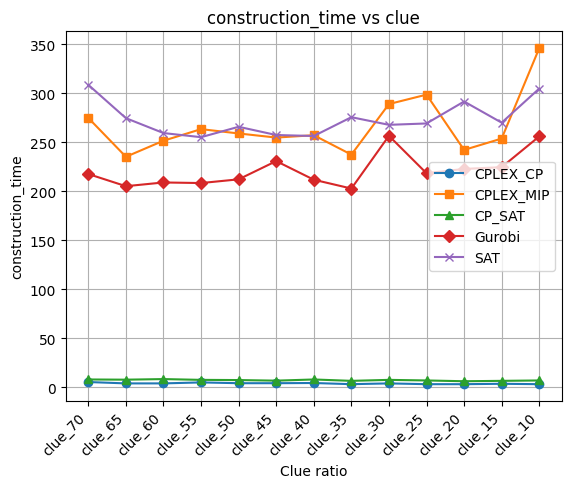

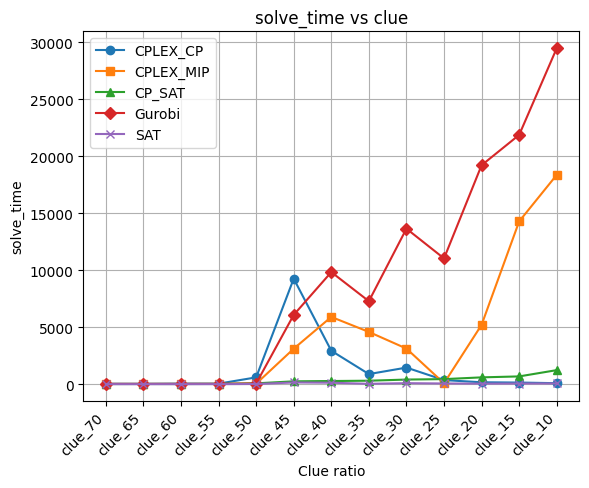

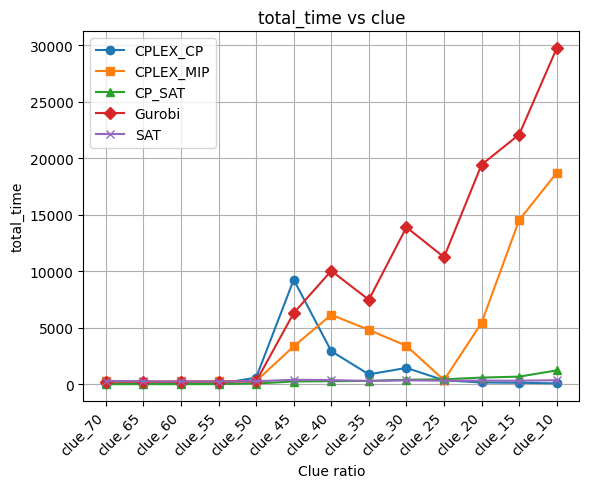

In [18]:
features = ['construction_time', 'solve_time', 'total_time']

unique_solvers = my_df_solver_mean['solver'].unique()
available_markers = ['o', 's', '^', 'D', 'x', '*', 'v']

solver_marker_map = {solver: available_markers[i % len(available_markers)] for i, solver in enumerate(unique_solvers)}

for feature in features:
    for solver, data in my_df_solver_mean.groupby('solver'):
        plt.plot(data['clue_ratio'][::-1], data[feature][::-1], label = solver, marker=solver_marker_map[solver])

    plt.xticks(rotation=45, ha="right")
    plt.xlabel('Clue ratio')
    plt.ylabel(feature)
    plt.title(f"{feature} vs clue")
    plt.legend()
    plt.grid(True)
    plt.show()